## Tutorial to Using EvalNLP 🚀

Welcome to the **EvalNLP Framework Tutorial**! In this notebook, you'll learn how to use EvalNLP to analyze and debug a sentiment analysis model. We'll focus on two sentences:
1. A sentence where the model **correctly classifies** the input.
2. A sentence where the model **misclassifies** the input.

By the end of this tutorial, you'll be able to:
- Load a pre-trained model and tokenizer.
- Generate and visualize explanations for model predictions.
- Evaluate explanations using metrics.
- Use explanations to understand and debug model's decisions.

Let's get started!

### **1: Setup**

Before we begin, let's load the necessary components:
1. **Pre-trained Model and Tokenizer**: We'll use a Roberta-base model fine-tuned for sentiment analysis.
2. **Explainers**: We'll use Shap, LIME, ShapIQ, Integrated Gradients, GradientxInput, Saliency,DeepLift, GuidedBackprop to generate explanations.
3. **Evaluators**: We'll use Faithfulness, Plausibility, and Complexity metrics to evaluate the explanations.
4. **Benchmark Class**: This will help us manage the evaluation process.

Let's initialize these components.

In [1]:
import sys
sys.path.append('..')
from XAIbenchmark import XAIFramework
import warnings

warnings.filterwarnings("ignore")

%load_ext autoreload
%autoreload 2

d:\EvalNLP\venv\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Model and Tokenizer

In [2]:
from transformers import AutoModelForSequenceClassification, AutoTokenizer

model_name = "cardiffnlp/twitter-xlm-roberta-base-sentiment"
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForSequenceClassification.from_pretrained(model_name)

Explainers

In [3]:
from explainers import InputXGradientExplainer, IntegratedGradientsExplainer, DeepLiftExplainer, LimeExplainer, SHAPExplainer, SHAPIQExplainer, GuidedBackpropExplainer

ig= IntegratedGradientsExplainer(model,tokenizer)
gb= GuidedBackpropExplainer(model,tokenizer)
dl= DeepLiftExplainer(model,tokenizer)
ixg= InputXGradientExplainer(model,tokenizer,multiply_by_inputs=True)
g= InputXGradientExplainer(model,tokenizer,multiply_by_inputs=False)
lime= LimeExplainer(model,tokenizer)
shap= SHAPExplainer(model,tokenizer)
shapiq= SHAPIQExplainer(model,tokenizer)

Evaluators

In [4]:
from evaluators import AUCTPEvaluator, SoftComprehensivenessEvaluator, SoftSufficiencyEvaluator, FADEvaluator, SparsenessEvaluator, ComplexityEvaluator, IOUF1Evaluator,TokenF1Evaluator, AUPRCEvaluator

sc= SoftComprehensivenessEvaluator(model,tokenizer)
ss= SoftSufficiencyEvaluator(model,tokenizer)
fad= FADEvaluator(model,tokenizer)
sp= SparsenessEvaluator(model,tokenizer)
cx= ComplexityEvaluator(model,tokenizer)
auctp= AUCTPEvaluator(model,tokenizer)
iou_f1= IOUF1Evaluator(model,tokenizer)
token_f1= TokenF1Evaluator(model,tokenizer)
auprc= AUPRCEvaluator(model,tokenizer)

XAIBenchmark Class

**Note:** If you don’t pass any explainers or evaluators while initializing this class, it defaults to all explainers/evaluators.

In [5]:
xai_framework = XAIFramework(model, tokenizer,explainers=[dl,ig,gb,shap,lime,shapiq,ixg,g], evaluators=[sp,cx,token_f1,iou_f1,auctp,auprc,sc,ss,fad])

### **2: Explain Sentence 1 - Correct Classification**

In this section, we'll analyze a sentence where the model **correctly classifies** the input. We'll:
1. Generate the model's output.
2. Explain the model's decision using different explainer.
3. Visualize the explanations.
4. Analyze why the model made the correct decision.

**Sentence**: `"The movie was great, I loved it!"` 
**True Label**: `"Positive"`

In [6]:
example_1= "The movie was great, I loved it!"
xai_framework.classify_text(example_1)

{'negative': 0.012726591899991035,
 'neutral': 0.03889957070350647,
 'positive': 0.9483739137649536}

Explain

In [7]:
exps_1= xai_framework.explain(input_data=example_1,target_label="positive")

Running Inference: 100%|██████████| 16/16 [00:09<00:00,  1.60it/s]


Visualize

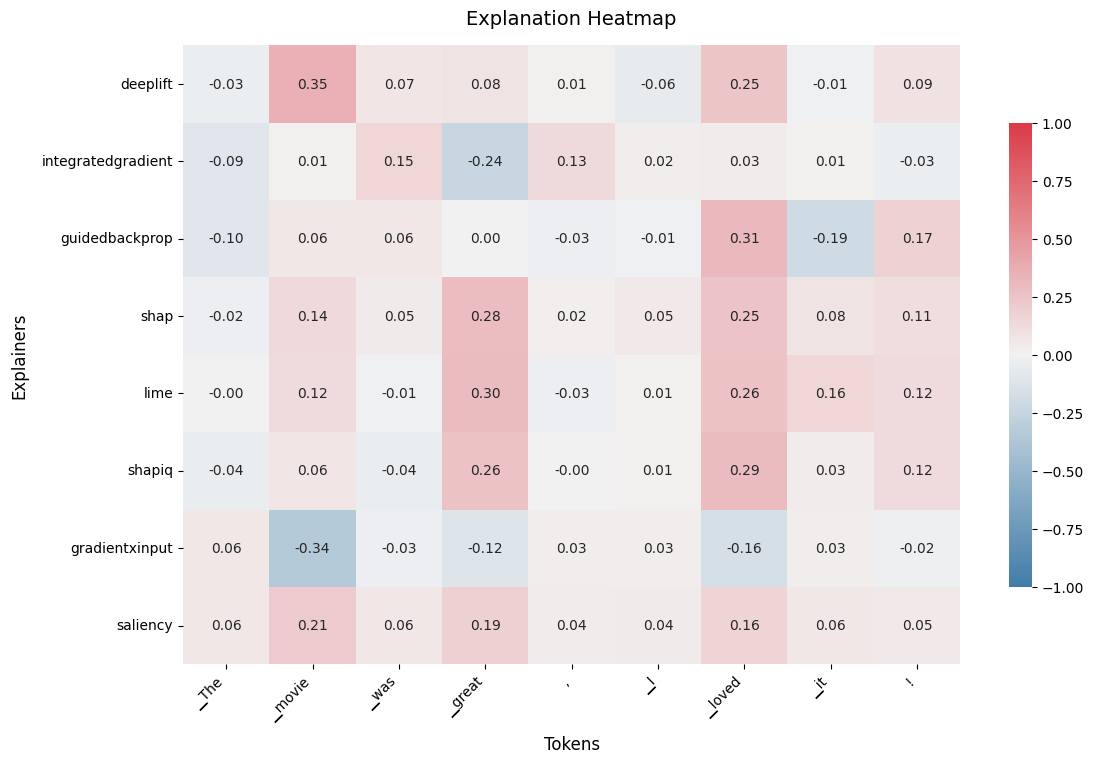

In [8]:
xai_framework.visualize(exps_1)

📌 How to interpret explanation scores?

This heatmap shows how different explanation methods (feature attribution techniques) assign importance scores to different words (tokens) in a sentence.

Each row represents a different explanation method, and each column represents a token (word or punctuation) from the input sentence.

🔴 Red (Positive Score) → Word contributes positively to the prediction.

🔵 Blue (Negative Score) → Word contributes negatively to the prediction.

⚪ White/Neutral (Close to 0) → Word has little to no effect on the prediction.

Analyze

🧐 Use these explanations to try to understand why the model classified this sentence as positive:

1. The words "great" and "loved" have strong positive contributions across almost all explanation methods (e.g. "great":  SHAP: 0.28, LIME: 0.33 and "loved": SHAP: 0.25, LIME:0.14)
2. The exclamation mark (!) adds emphasis, further supporting the positive classification (e.g. SHAP: 0.11, LIME: 0.10, DeepLift: 0.09)
3. Neutral words like "The", "was", "I", and "it" do not detract from the overall positive sentiment as they have low or near-zero scores.


### **3: Explain Sentence 2 - Misclassification**

In this section, we'll analyze a sentence where the model **misclassifies** the input. We'll:
1. Generate the model's output.
2. Explain the model's decision using different explainers
3. Visualize the explanations.
4. Analyze why the model misclassified the sentence and how explanations can help debug the issue.

**Sentence**: `"Great movie for a great nap!"` **True label**: `"Negative"`

In [9]:
example_2= "Great movie for a great nap!"
# sentence= "The movie was not bad, but it could have been better."
xai_framework.classify_text(example_2)

{'negative': 0.01373552717268467,
 'neutral': 0.06385013461112976,
 'positive': 0.9224143624305725}

Explain

In [10]:
exps_2= xai_framework.explain(input_data=example_2,target_label="positive")

Running Inference: 100%|██████████| 11/11 [00:03<00:00,  2.92it/s]


Visualize

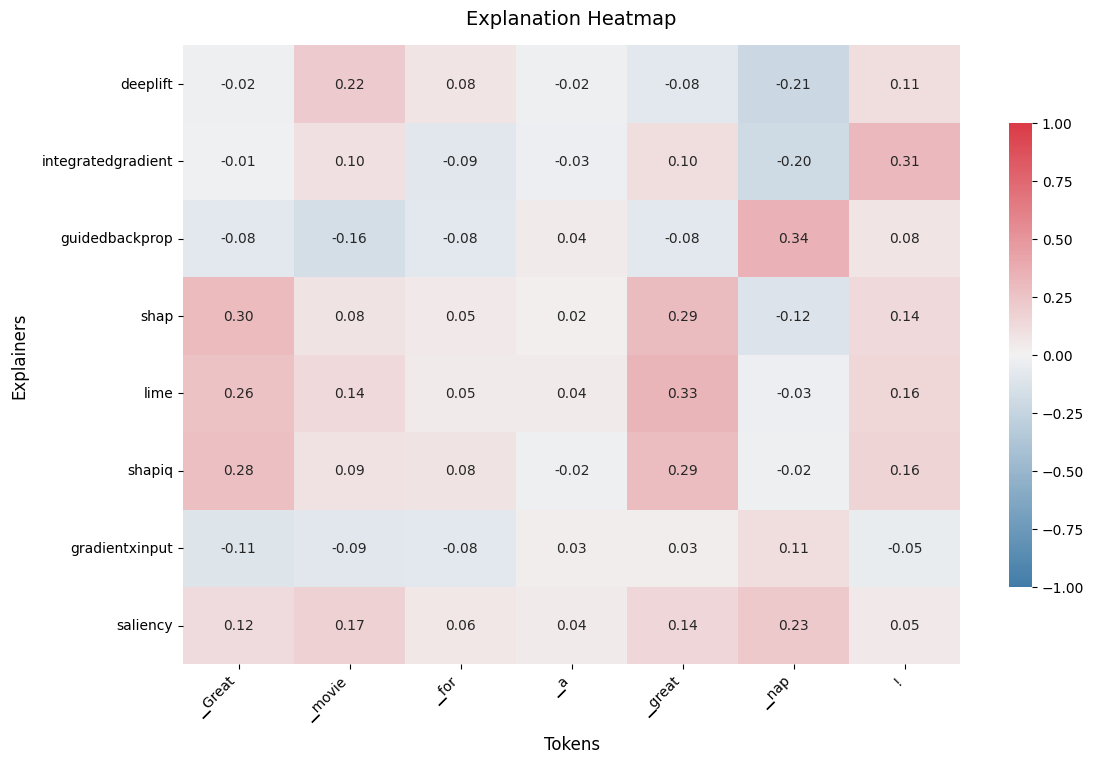

In [11]:
xai_framework.visualize(exps_2)

Analyze

🧐 Let’s analyze the explanation scores to understand why the model predicted the sentence as positive when it is actually negative (sarcastic). 

1. It heavily weighted the word "great" as a strong positive signal, ignoring the sarcastic context (e.g SHAP: 0.30, LIME: 0.26, SHAPIQ: 0.25)
2. The exclamation mark (!) was interpreted as adding positive emphasis rather than sarcasm (e.g. SHAP: 0.14, LIME: 0.19, IntegratedGradient:0.31)  
3. The word "nap" has negative scores (e.g SHAP: -0.12, LIME: -0.18),suggesting the model associates it with a negative sentiment, but not as strongly as positive contribution of  "great" and "!". 
4. It failed to properly interpret the phrase "great nap" as negative (implying the movie was boring), so context of phrases like "great nap" is not being captured as a single meaningful unit.
5. The training data might lack sufficient examples of sarcastic or nuanced language, causing the model to misinterpret such sentences.


### **4: Evaluate**

In [12]:
xai_framework.evaluate_single_sentence(example_1, target_label="positive",human_rationale=[0,0,0,0,1,0,0,1,0,0,0])

explainer deeplift
explainer integratedgradient
explainer guidedbackprop
explainer shap
explainer lime


Running Inference: 100%|██████████| 16/16 [00:06<00:00,  2.37it/s]


explainer shapiq
explainer gradientxinput
explainer saliency


Evaluator,Area under PR Curve,Area under TP Curve,Complexity,Feature Ablation Drop,IOU F1 score,Soft Comprehensiveness,Soft Sufficiency,Sparseness,Token F1 score
Explainer,,,,,,,,,
deeplift,0.154762,0.35,0.169771,1.0,0.0,0.841207,0.000160,0.365314,0.363636
gradientxinput,0.416667,0.75,0.182295,1.0,0.0,0.632616,0.000000,0.294198,0.363636
guidedbackprop,0.122520,0.65,0.177011,1.0,0.0,0.632598,0.000000,0.327969,0.363636
integratedgradient,0.287500,0.95,0.186528,1.0,0.0,0.632606,0.000172,0.271573,0.363636
lime,0.160714,0.15,0.161668,1.0,0.0,0.632606,0.000161,0.404443,0.363636
saliency,0.136806,0.15,0.200548,1.0,0.0,0.842928,0.000158,0.150652,0.363636
shap,0.148214,0.15,0.170381,1.0,0.0,0.734450,0.000158,0.361416,0.363636
shapiq,0.163095,0.15,0.165023,1.0,0.0,0.632606,0.000162,0.385502,0.363636


In [13]:
xai_framework.evaluate_single_sentence(example_2, target_label="positive",human_rationale=[0, 1, 0, 0, 0,1,0,0,0])

explainer deeplift
explainer integratedgradient
explainer guidedbackprop
explainer shap
explainer lime


Running Inference: 100%|██████████| 11/11 [00:02<00:00,  3.76it/s]


explainer shapiq
explainer gradientxinput
explainer saliency


Evaluator,Area under PR Curve,Area under TP Curve,Complexity,Feature Ablation Drop,IOU F1 score,Soft Comprehensiveness,Soft Sufficiency,Sparseness,Token F1 score
Explainer,,,,,,,,,
deeplift,0.613095,0.65,0.219171,1.0,0.0,0.739255,0.000166,0.134310,0.444444
gradientxinput,0.633333,0.95,0.217560,1.0,0.0,0.606610,0.000176,0.157087,0.444444
guidedbackprop,0.613095,0.45,0.217463,1.0,0.0,0.788370,0.000212,0.122200,0.444444
integratedgradient,0.196429,0.25,0.212895,1.0,0.0,0.606650,0.000164,0.175958,0.444444
lime,0.163095,0.15,0.192412,1.0,0.0,0.742001,0.000197,0.263353,0.444444
saliency,1.000000,0.45,0.228947,1.0,0.0,0.606532,0.000165,0.072432,0.444444
shap,0.175595,0.25,0.185745,1.0,0.0,0.606651,0.000166,0.309779,0.444444
shapiq,0.195833,0.15,0.204106,1.0,0.0,0.742001,0.000175,0.241401,0.444444
